<a href="https://colab.research.google.com/github/mysteryea7107/Comparative-Evaluation-of-OLS-Ridge-Lasso-Elastic-Net-and-PLS_for-Baseball-Player-Salary-Prediction/blob/main/Notebooks/Comparative_Evaluation_of_OLS%2C_Ridge%2C_Lasso%2C_Elastic_Net%2C_and_PLS_for_Baseball_Player_Salary_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import root_mean_squared_error, r2_score
import seaborn as sns
from scipy import stats
# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define the file path
file_path = '/content/drive/MyDrive/PUP Grad Data Science/1st Sem/STAT 516 Predictive Modelling Using R Software and Python Application /Baseball/Hitters.csv'




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
### EDA
df = pd.read_csv(file_path)

df.head()

,Unnamed: 0,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,...,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,-Andy Allanson,293,66,1,30,29,14,1,293,66,...,30,29,14,A,E,446,33,20,NaN,A
1,-Alan Ashby,315,81,7,24,38,39,14,3449,835,...,321,414,375,N,W,632,43,10,475.0,N
2,-Alvin Davis,479,130,18,66,72,76,3,1624,457,...,224,266,263,A,W,880,82,14,480.0,A
3,-Andre Dawson,496,141,20,65,78,37,11,5628,1575,...,828,838,354,N,E,200,11,3,500.0,N
4,-Andres Galarraga,321,87,10,39,42,30,2,396,101,...,48,46,33,N,E,805,40,4,91.5,N


In [11]:
print('Shape of the data:{}'.format(df.shape))

Shape of the data:(263, 21)


In [10]:
#Remove observations with missing target variable (Salary)
df = df.dropna(subset=['Salary']).reset_index(drop=True)



In [12]:
df = df.replace('?', np.nan).dropna()
print('Shape of the data:{}'.format(df.shape))

Shape of the data:(263, 21)


In [13]:
print('Check data types)\n{}\n'.format(df.dtypes))

Check data types)
Unnamed: 0     object
AtBat           int64
Hits            int64
HmRun           int64
Runs            int64
RBI             int64
Walks           int64
Years           int64
CAtBat          int64
CHits           int64
CHmRun          int64
CRuns           int64
CRBI            int64
CWalks          int64
League         object
Division       object
PutOuts         int64
Assists         int64
Errors          int64
Salary        float64
NewLeague      object
dtype: object



In [14]:
df.select_dtypes(include=[np.number]).corr()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
AtBat,1.000000,0.963969,0.555102,0.899829,0.796015,0.624448,0.012725,0.207166,0.225341,0.212422,0.237278,0.221393,0.132926,0.309607,0.342117,0.325577,0.394771
Hits,0.963969,1.000000,0.530627,0.910630,0.788478,0.587311,0.018598,0.206678,0.235606,0.189364,0.238896,0.219384,0.122971,0.299688,0.303975,0.279876,0.438675
HmRun,0.555102,0.530627,1.000000,0.631076,0.849107,0.440454,0.113488,0.217464,0.217496,0.492526,0.258347,0.349858,0.227183,0.250931,-0.161602,-0.009743,0.343028
Runs,0.899829,0.910630,0.631076,1.000000,0.778692,0.697015,-0.011975,0.171811,0.191327,0.229701,0.237831,0.202335,0.163700,0.271160,0.179258,0.192609,0.419859
RBI,0.796015,0.788478,0.849107,0.778692,1.000000,0.569505,0.129668,0.278126,0.292137,0.442190,0.307226,0.387777,0.233619,0.312065,0.062902,0.150155,0.449457
Walks,0.624448,0.587311,0.440454,0.697015,0.569505,1.000000,0.134793,0.269450,0.270795,0.349582,0.332977,0.312697,0.429140,0.280855,0.102523,0.081937,0.443867
Years,0.012725,0.018598,0.113488,-0.011975,0.129668,0.134793,1.000000,0.915681,0.897844,0.722371,0.876649,0.863809,0.837524,-0.020019,-0.085118,-0.156512,0.400657
CAtBat,0.207166,0.206678,0.217464,0.171811,0.278126,0.269450,0.915681,1.000000,0.995057,0.801676,0.982747,0.950730,0.906712,0.053393,-0.007897,-0.070478,0.526135
CHits,0.225341,0.235606,0.217496,0.191327,0.292137,0.270795,0.897844,0.995057,1.000000,0.786652,0.984542,0.946797,0.890718,0.067348,-0.013144,-0.068036,0.548910
CHmRun,0.212422,0.189364,0.492526,0.229701,0.442190,0.349582,0.722371,0.801676,0.786652,1.000000,0.825625,0.927903,0.810878,0.093822,-0.188886,-0.165369,0.524931


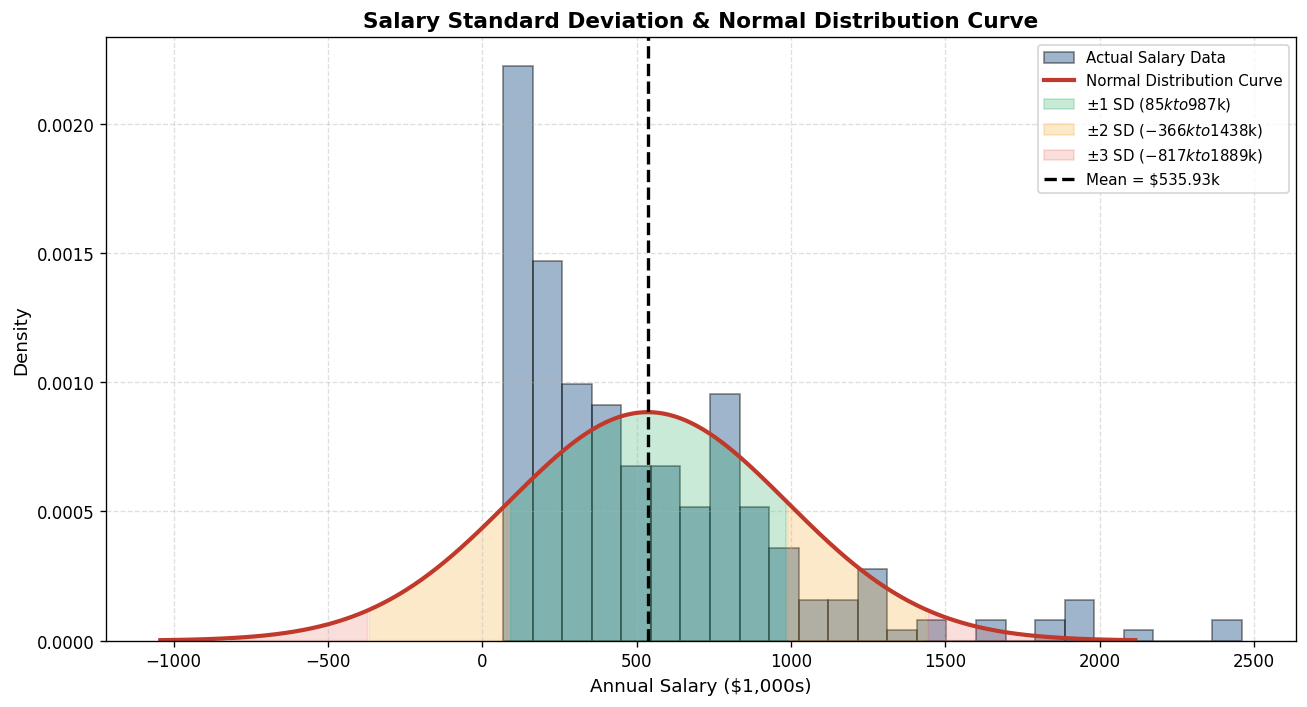

Total Players (with Salary) : 263
Mean Salary (μ)             : $535.93k
Standard Deviation (σ)      : $451.12k
Minimum Salary              : $67.50k
Maximum Salary              : $2460.00k


In [15]:
# 3. Define salary and calculate Mean and Standard Deviation
salary = df["Salary"]
mean_sal = salary.mean()
std_sal = salary.std()

# 4. Build the Standard Deviation Bell Curve Plot
plt.figure(figsize=(11, 6), dpi=120)

# Plot actual Salary histogram (as probability density)
plt.hist(
    salary, bins=25, density=True, color="#2b5c8f", alpha=0.45,
    edgecolor="black", label="Actual Salary Data"
)

# Create theoretical Normal Bell Curve using Salary's Mean & SD
x = np.linspace(mean_sal - 3.5 * std_sal, mean_sal + 3.5 * std_sal, 500)
y = stats.norm.pdf(x, mean_sal, std_sal)
plt.plot(x, y, color="#c0392b", linewidth=2.5, label="Normal Distribution Curve")

# Shade +/- 1 SD, +/- 2 SD, and +/- 3 SD bands
plt.fill_between(
    x, y, where=(np.abs(x - mean_sal) <= std_sal),
    color="#27ae60", alpha=0.25, label=f"±1 SD (${mean_sal - std_sal:.0f}k to ${mean_sal + std_sal:.0f}k)"
)
plt.fill_between(
    x, y, where=((np.abs(x - mean_sal) > std_sal) & (np.abs(x - mean_sal) <= 2 * std_sal)),
    color="#f39c12", alpha=0.22, label=f"±2 SD (${mean_sal - 2*std_sal:.0f}k to ${mean_sal + 2*std_sal:.0f}k)"
)
plt.fill_between(
    x, y, where=((np.abs(x - mean_sal) > 2 * std_sal) & (np.abs(x - mean_sal) <= 3 * std_sal)),
    color="#e74c3c", alpha=0.18, label=f"±3 SD (${mean_sal - 3*std_sal:.0f}k to ${mean_sal + 3*std_sal:.0f}k)"
)

# Plot vertical line for the Mean
plt.axvline(mean_sal, color="black", linestyle="--", linewidth=2, label=f"Mean = ${mean_sal:.2f}k")

# Formatting and labels
plt.title("Salary Standard Deviation & Normal Distribution Curve", fontsize=13, fontweight="bold")
plt.xlabel("Annual Salary ($1,000s)", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.legend(loc="upper right", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Print Summary Statistics
print(f"Total Players (with Salary) : {len(salary)}")
print(f"Mean Salary (μ)             : ${mean_sal:.2f}k")
print(f"Standard Deviation (σ)      : ${std_sal:.2f}k")
print(f"Minimum Salary              : ${salary.min():.2f}k")
print(f"Maximum Salary              : ${salary.max():.2f}k")

In [16]:
##Normalize Salary using Natural Log Transformation
log_salary = np.log(salary)

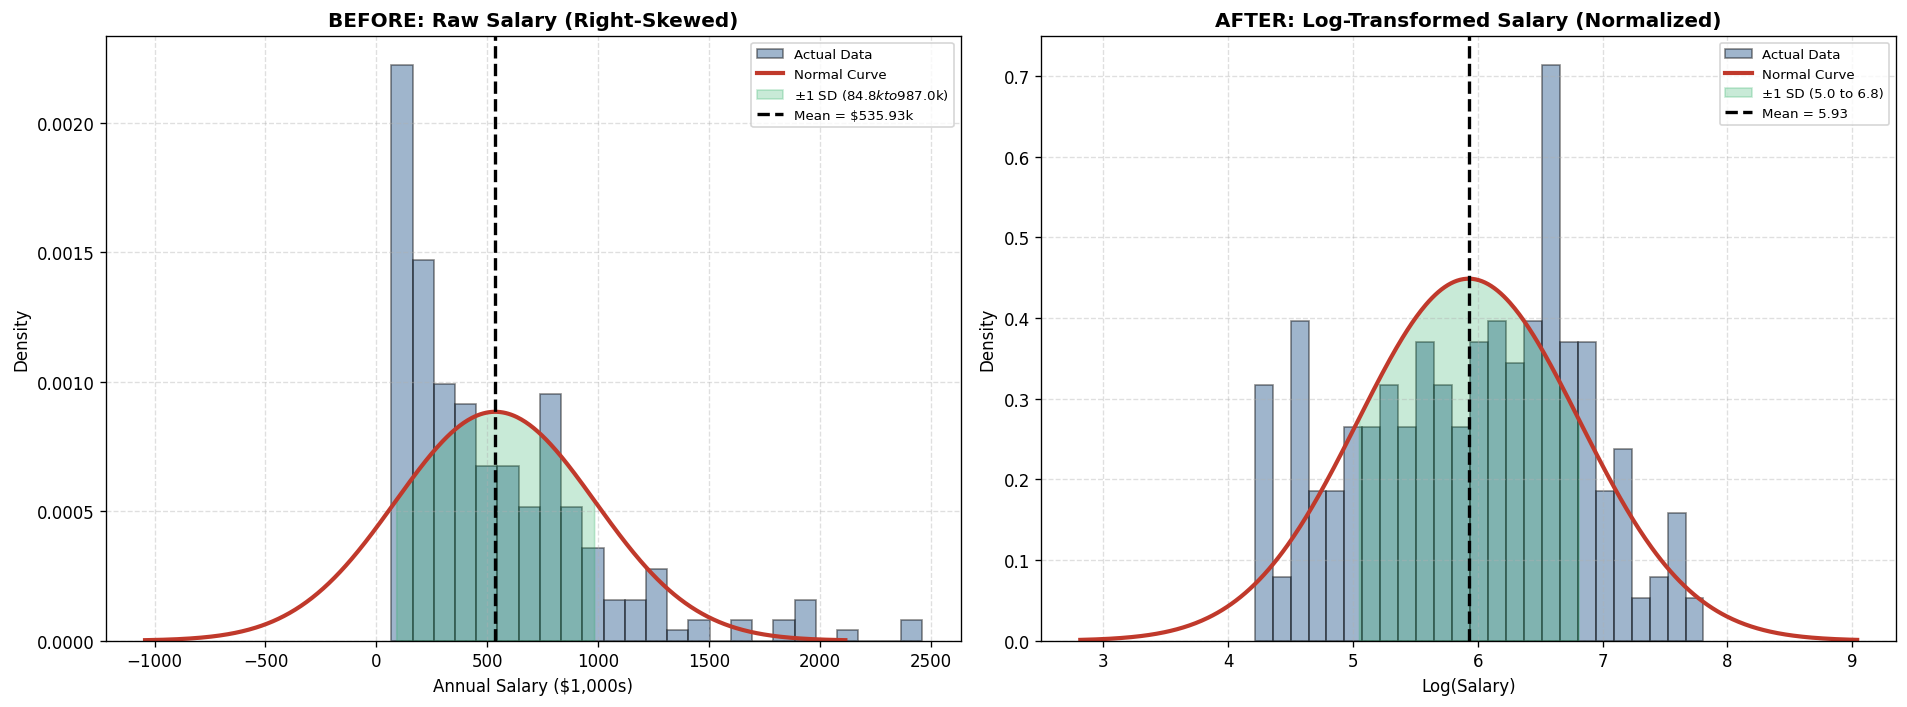

NORMALITY COMPARISON SUMMARY
Raw Salary Skewness : 1.580 | Shapiro p-value: 3.3074e-15
Log Salary Skewness : -0.181 | Shapiro p-value: 0.0000


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Map the active variable name
raw_salary = salary

# Define the missing helper function to plot the histograms and normal curve overlays
def plot_normal_curve(ax, data, title, xlabel, unit_prefix="", unit_suffix=""):
    mean_val = data.mean()
    std_val = data.std()

    # Plot histogram density
    ax.hist(data, bins=25, density=True, color="#2b5c8f", alpha=0.45, edgecolor="black", label="Actual Data")

    # Generate theoretical Normal Bell Curve
    x_vals = np.linspace(mean_val - 3.5 * std_val, mean_val + 3.5 * std_val, 500)
    y_vals = stats.norm.pdf(x_vals, mean_val, std_val)
    ax.plot(x_vals, y_vals, color="#c0392b", linewidth=2.5, label="Normal Curve")

    # Fill standard deviation bands
    ax.fill_between(x_vals, y_vals, where=(np.abs(x_vals - mean_val) <= std_val),
                    color="#27ae60", alpha=0.25, label=f"±1 SD ({unit_prefix}{mean_val - std_val:.1f}{unit_suffix} to {unit_prefix}{mean_val + std_val:.1f}{unit_suffix})")

    # Add Mean vertical line and formatting
    ax.axvline(mean_val, color="black", linestyle="--", linewidth=2, label=f"Mean = {unit_prefix}{mean_val:.2f}{unit_suffix}")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.4)

# Create Side-by-Side Comparison Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# Left: Original Skewed Salary
plot_normal_curve(
    axes[0], raw_salary,
    title="BEFORE: Raw Salary (Right-Skewed)",
    xlabel="Annual Salary ($1,000s)",
    unit_prefix="$", unit_suffix="k"
)

# Right: Log-Normalized Salary
plot_normal_curve(
    axes[1], log_salary,
    title="AFTER: Log-Transformed Salary (Normalized)",
    xlabel="Log(Salary)",
    unit_prefix="", unit_suffix=""
)

plt.tight_layout()
plt.show()

# Print Normality Test Comparison (Shapiro-Wilk Test)
_, p_raw = stats.shapiro(raw_salary)
_, p_log = stats.shapiro(log_salary)

print("=" * 55)
print("NORMALITY COMPARISON SUMMARY")
print("=" * 55)
print(f"Raw Salary Skewness : {stats.skew(raw_salary):.3f} | Shapiro p-value: {p_raw:.4e}")
print(f"Log Salary Skewness : {stats.skew(log_salary):.3f} | Shapiro p-value: {p_log:.4f}")
print("=" * 55)

In [18]:
# ==============================================================================
# BLOCK: DATA PREPARATION & LOG-NORMALIZED TRAIN/TEST SPLIT
# Report Alignment: Supports Section c (Data Preparation) & Section d (Setup)
# ==============================================================================

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import root_mean_squared_error, r2_score

# Silence solver convergence notices during hyperparameter grid search
warnings.filterwarnings("ignore")

# 1. Remove missing Salary records (reduces 322 players to 263 complete cases)
clean_df = df.dropna(subset=["Salary"]).reset_index(drop=True)

# 2. Separate predictor features (X) and log-normalized target variable (y_log)
X = clean_df.drop(columns=["Salary"])
y_raw = clean_df["Salary"]
y_log = np.log(y_raw)

# 3. Convert categorical text columns (League, Division, NewLeague) into binary 0/1 columns
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Split into 80% Training Set and 20% Holdout Test Set using a fixed seed (516)
RANDOM_STATE = 516
X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
    X_encoded, y_log, y_raw, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training Samples : {X_train.shape[0]} players | Features: {X_train.shape[1]}")
print(f"Testing Samples  : {X_test.shape[0]} players | Features: {X_test.shape[1]}")

Training Samples : 210 players | Features: 281
Testing Samples  : 53 players | Features: 281


In [20]:
# BLOCK 4: REPORT VISUALIZATIONS
# Report Alignment: Section g (Predicted-vs-Actual, Tuning, & Coefficient Plots)
# ==============================================================================

# Identify the best-performing model automatically from Row 0 of results_table
best_method = results_table.loc[0, "Method"]
best_preds = test_predictions_dollars[best_method]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=120)

# --- Visualization 1: Predicted vs. Actual Salary (Best Model) ---
axes[0].scatter(y_test_raw, best_preds, color="#2b5c8f", alpha=0.8, edgecolors="k", s=60)
min_val = min(y_test_raw.min(), best_preds.min())
max_val = max(y_test_raw.max(), best_preds.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Prediction (y = x)")

axes[0].set_title(f"Predicted vs. Actual Salary\n(Best Model: {best_method})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Actual Salary ($1,000s)", fontsize=10)
axes[0].set_ylabel("Predicted Salary ($1,000s)", fontsize=10)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

SECTION e: SELECTED 10-FOLD CV TUNING SETTINGS
OLS                  : None (Unregularized Baseline)
PLS Optimal Comps    : 6 components
Ridge Best Lambda    : 19.1164
Lasso Best Lambda    : 0.0030
Elastic Net Settings : l1_ratio = 0.70 | Lambda = 0.0070


In [26]:
#  TEST EVALUATION & RESULTS TABLE
# Report Alignment: Section f (Results Table with Test RMSE and R-Squared)
# ==============================================================================

# 1. Predict on test set (in log scale) and convert back to dollars ($1,000s) via np.exp()
test_predictions_dollars = {
    "OLS": np.exp(ols_pipe.predict(X_test)),
    "PLS": np.exp(pls_tuner.predict(X_test).ravel()),
    "Ridge": np.exp(ridge_pipe.predict(X_test)),
    "Lasso": np.exp(lasso_pipe.predict(X_test)),
    "Elastic Net": np.exp(enet_pipe.predict(X_test))
}

# 2. Calculate Test RMSE ($1,000s) and Test R-Squared for each model
results_list = []
for model_name, pred_dollars in test_predictions_dollars.items():
    rmse_val = root_mean_squared_error(y_test_raw, pred_dollars)
    r2_val = r2_score(y_test_raw, pred_dollars)
    results_list.append({
        "Method": model_name,
        "Test RMSE ($1000s)": round(rmse_val, 3),
        "Test R-Squared": round(r2_val, 4)
    })

# 3. Format and display the final results table sorted from lowest error to highest
results_table = pd.DataFrame(results_list).sort_values(by="Test RMSE ($1000s)").reset_index(drop=True)

print("=" * 60)
print("TEST SET PERFORMANCE TABLE")
print("=" * 60)
display(results_table)

TEST SET PERFORMANCE TABLE


,Method,Test RMSE ($1000s),Test R-Squared
0,PLS,512.936,0.0786
1,Ridge,515.650,0.0688
2,OLS,551.575,-0.0654
3,Elastic Net,553.717,-0.0737
4,Lasso,595.896,-0.2435


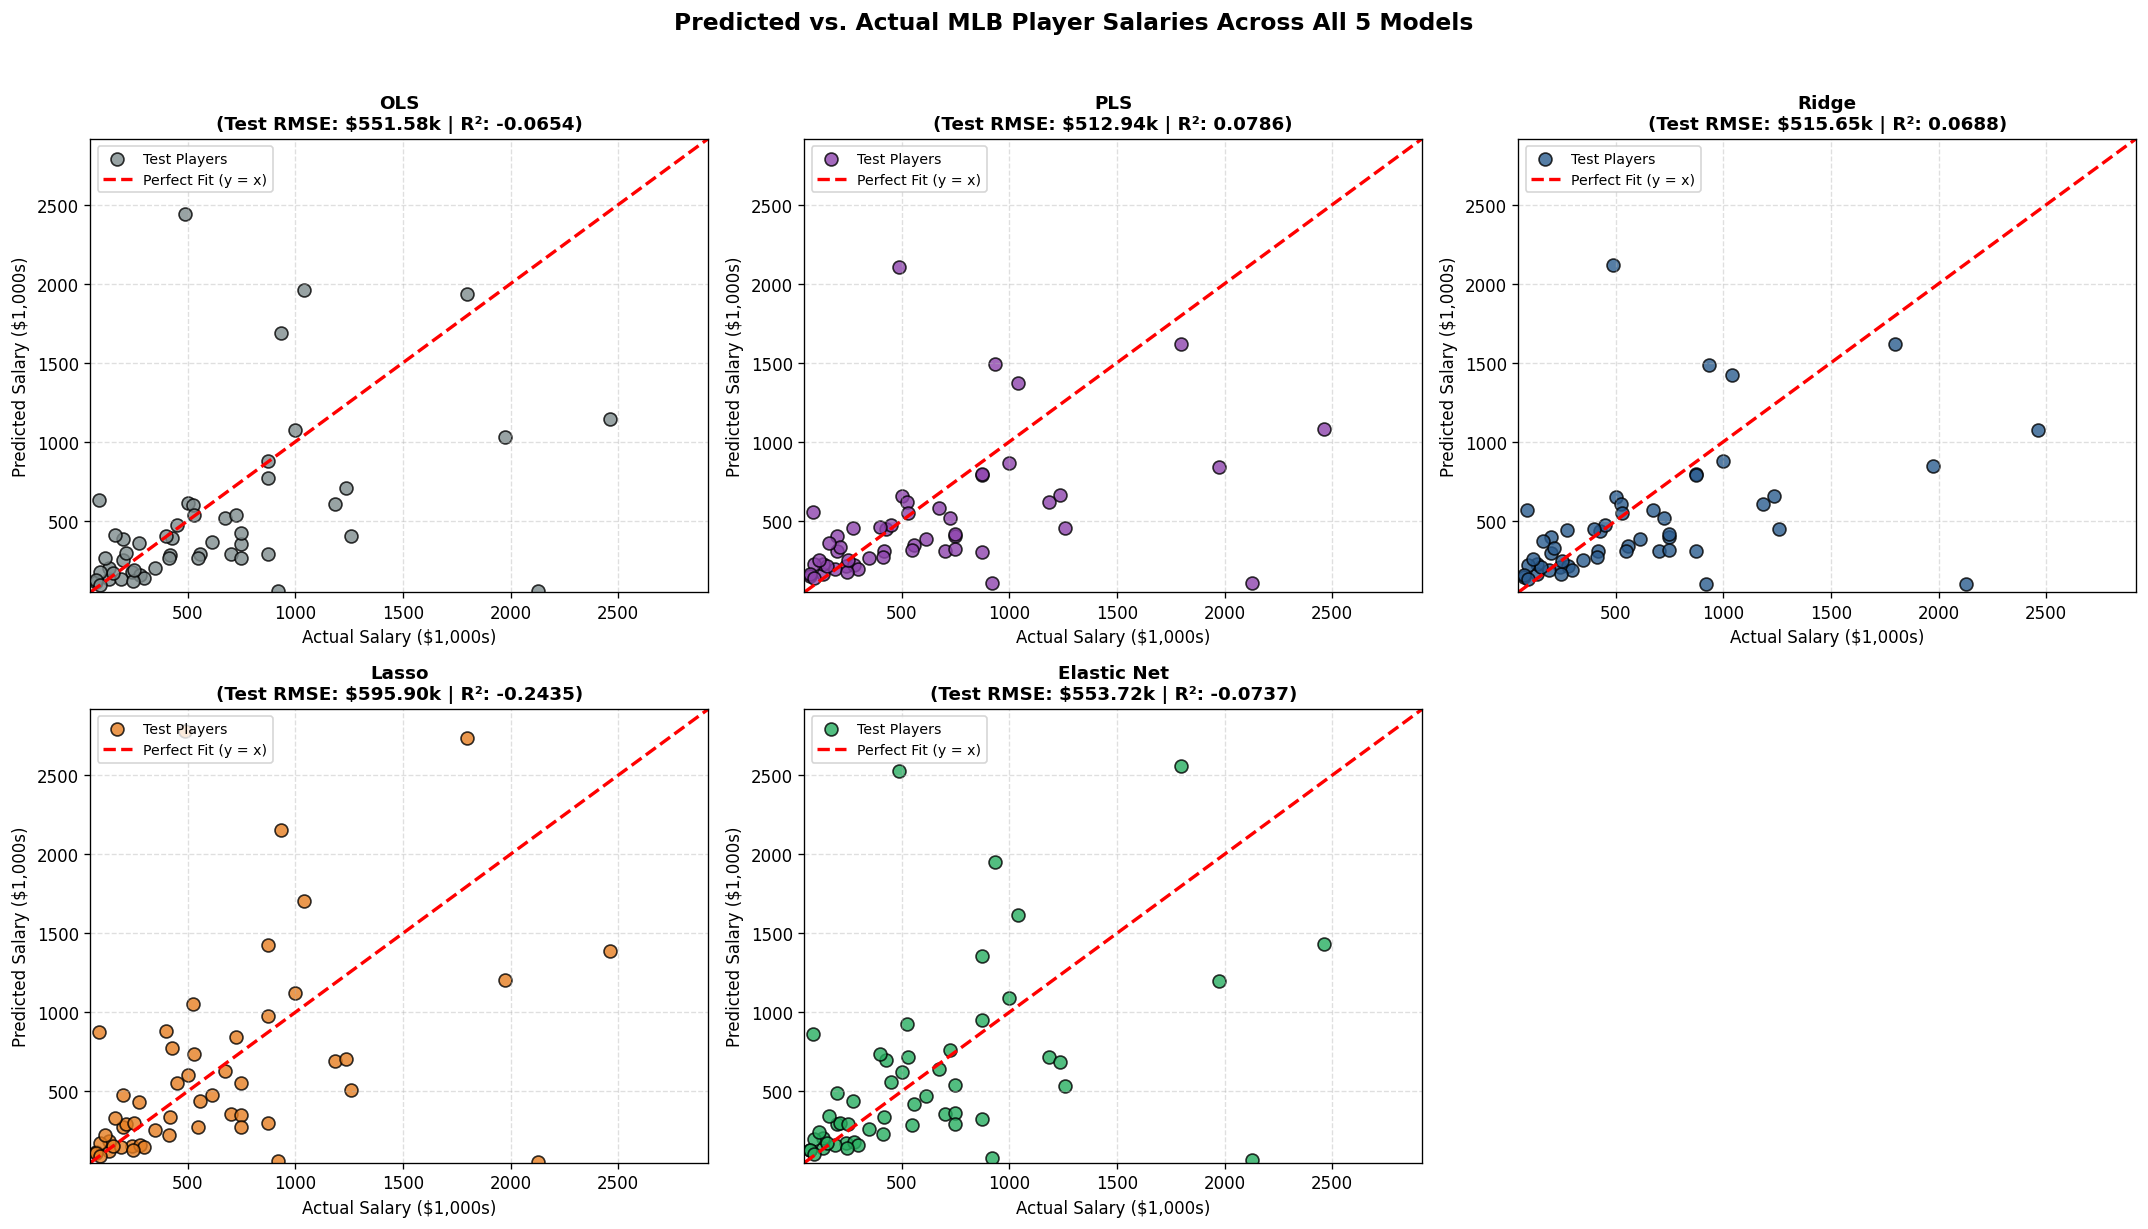

In [28]:
# ==============================================================================
# PREDICTED VS. ACTUAL VISUALIZATIONS FOR ALL 5 MODELS
# Report Alignment: Section g (Visual Comparison Across All Methods)
# ==============================================================================

# 1. Create a 2x3 subplot grid (5 model plots + 1 empty slot turned off)
fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=120)
axes = axes.flatten()  # Flatten 2D grid into a 1D list for easy looping

# 2. Define model order and distinct colors for visual clarity
model_order = ["OLS", "PLS", "Ridge", "Lasso", "Elastic Net"]
colors = ["#7f8c8d", "#8e44ad", "#2b5c8f", "#e67e22", "#27ae60"]

# 3. Determine shared axis limits across all models for a fair visual comparison
all_preds = np.concatenate([test_predictions_dollars[m] for m in model_order])
global_min = min(y_test_raw.min(), all_preds.min()) * 0.9
global_max = max(y_test_raw.max(), all_preds.max()) * 1.05

# 4. Loop through each model and generate its Predicted vs. Actual scatter plot
for idx, (model_name, color) in enumerate(zip(model_order, colors)):
    ax = axes[idx]
    preds = test_predictions_dollars[model_name]

    # Extract RMSE and R-squared for this model from results_table
    metrics_row = results_table[results_table["Method"] == model_name].iloc[0]
    rmse_val = metrics_row["Test RMSE ($1000s)"]
    r2_val = metrics_row["Test R-Squared"]

    # Plot scatter points and the ideal 45-degree reference line (y = x)
    ax.scatter(y_test_raw, preds, color=color, alpha=0.8, edgecolors="k", s=60, label="Test Players")
    ax.plot([global_min, global_max], [global_min, global_max], "r--", lw=2, label="Perfect Fit (y = x)")

    # Set consistent axis limits, titles, and gridlines
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    ax.set_title(
        f"{model_name}\n(Test RMSE: ${rmse_val:.2f}k | R²: {r2_val:.4f})",
        fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("Actual Salary ($1,000s)", fontsize=10)
    ax.set_ylabel("Predicted Salary ($1,000s)", fontsize=10)
    ax.legend(loc="upper left", fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.4)

# 5. Hide the unused 6th subplot panel in the bottom-right corner
axes[5].axis("off")

plt.suptitle("Predicted vs. Actual MLB Player Salaries Across All 5 Models", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


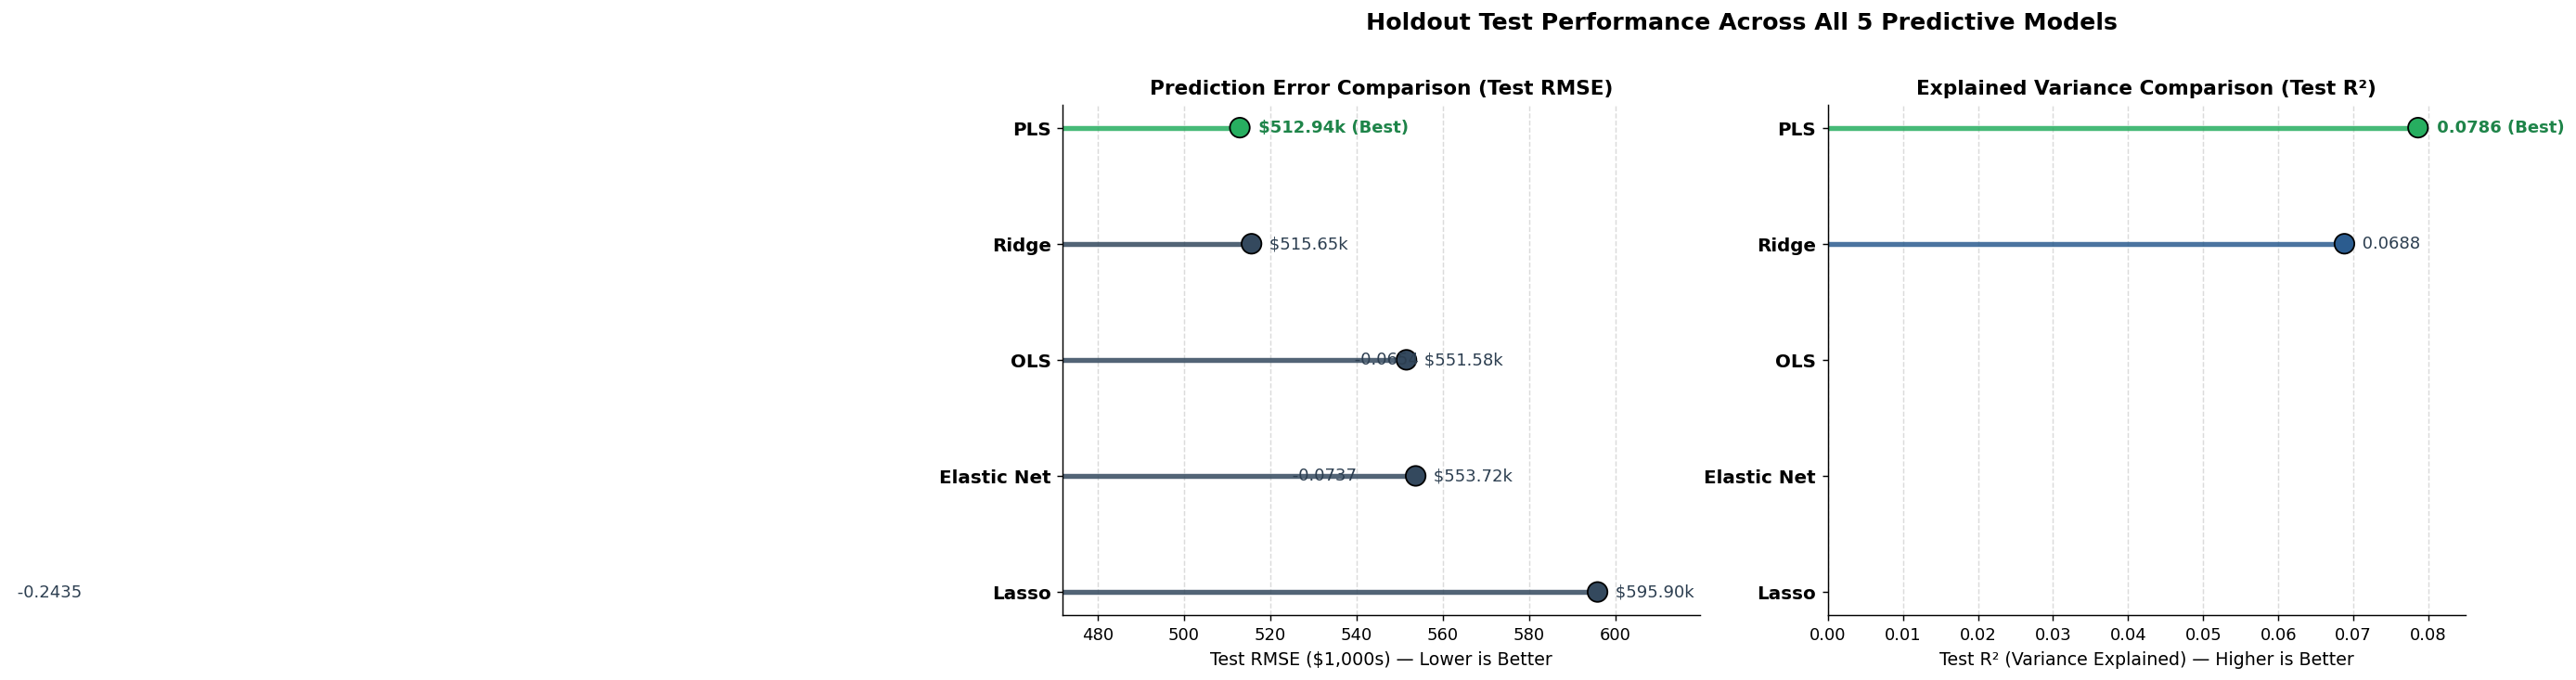

In [31]:
# ==============================================================================
# VISUAL MODEL PERFORMANCE COMPARISON (LOLLIPOP + R-SQUARED CHART)
# Report Alignment: Section g (Clear Visual Alternative to Plain Bar Charts)
# ==============================================================================

# 1. Sort results_table so the best model (lowest RMSE) appears at the top
plot_df = results_table.sort_values(by="Test RMSE ($1000s)", ascending=False).reset_index(drop=True)

models = plot_df["Method"]
rmse_vals = plot_df["Test RMSE ($1000s)"]
r2_vals = plot_df["Test R-Squared"]

# Highlight the best model (last row after descending sort) in emerald green; others in slate blue
best_rmse = rmse_vals.min()
best_r2 = r2_vals.max()
rmse_colors = ["#27ae60" if val == best_rmse else "#34495e" for val in rmse_vals]
r2_colors = ["#27ae60" if val == best_r2 else "#2b5c8f" for val in r2_vals]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=130)

# --- Panel 1: Test RMSE Lollipop Chart (Lower is Better) ---
y_pos = np.arange(len(models))
min_x_rmse = rmse_vals.min() * 0.92
max_x_rmse = rmse_vals.max() * 1.04

# Draw horizontal stems and circular lollipop heads
axes[0].hlines(y=y_pos, xmin=min_x_rmse, xmax=rmse_vals, color=rmse_colors, linewidth=3, alpha=0.85)
axes[0].scatter(rmse_vals, y_pos, color=rmse_colors, s=140, zorder=3, edgecolors="black", linewidth=1)

# Add exact dollar value labels next to each point
for idx, val in enumerate(rmse_vals):
    label_txt = f" ${val:.2f}k (Best)" if val == best_rmse else f" ${val:.2f}k"
    axes[0].text(val + (max_x_rmse - min_x_rmse) * 0.02, idx, label_txt,
                 va="center", fontsize=10, fontweight="bold" if val == best_rmse else "normal",
                 color="#1e8449" if val == best_rmse else "#2c3e50")

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(models, fontsize=11, fontweight="bold")
axes[0].set_xlim(min_x_rmse, max_x_rmse)
axes[0].set_xlabel("Test RMSE ($1,000s) — Lower is Better", fontsize=10.5)
axes[0].set_title("Prediction Error Comparison (Test RMSE)", fontsize=12, fontweight="bold")
axes[0].grid(True, axis="x", linestyle="--", alpha=0.45)
axes[0].spines[["top", "right"]].set_visible(False)

# --- Panel 2: Test R-Squared Lollipop Chart (Higher is Better) ---
min_x_r2 = max(0, r2_vals.min() * 0.90)
max_x_r2 = min(1.0, r2_vals.max() * 1.08)

axes[1].hlines(y=y_pos, xmin=min_x_r2, xmax=r2_vals, color=r2_colors, linewidth=3, alpha=0.85)
axes[1].scatter(r2_vals, y_pos, color=r2_colors, s=140, zorder=3, edgecolors="black", linewidth=1)

for idx, val in enumerate(r2_vals):
    label_txt = f" {val:.4f} (Best)" if val == best_r2 else f" {val:.4f}"
    axes[1].text(val + (max_x_r2 - min_x_r2) * 0.02, idx, label_txt,
                 va="center", fontsize=10, fontweight="bold" if val == best_r2 else "normal",
                 color="#1e8449" if val == best_r2 else "#2c3e50")

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(models, fontsize=11, fontweight="bold")
axes[1].set_xlim(min_x_r2, max_x_r2)
axes[1].set_xlabel("Test R² (Variance Explained) — Higher is Better", fontsize=10.5)
axes[1].set_title("Explained Variance Comparison (Test R²)", fontsize=12, fontweight="bold")
axes[1].grid(True, axis="x", linestyle="--", alpha=0.45)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Holdout Test Performance Across All 5 Predictive Models", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


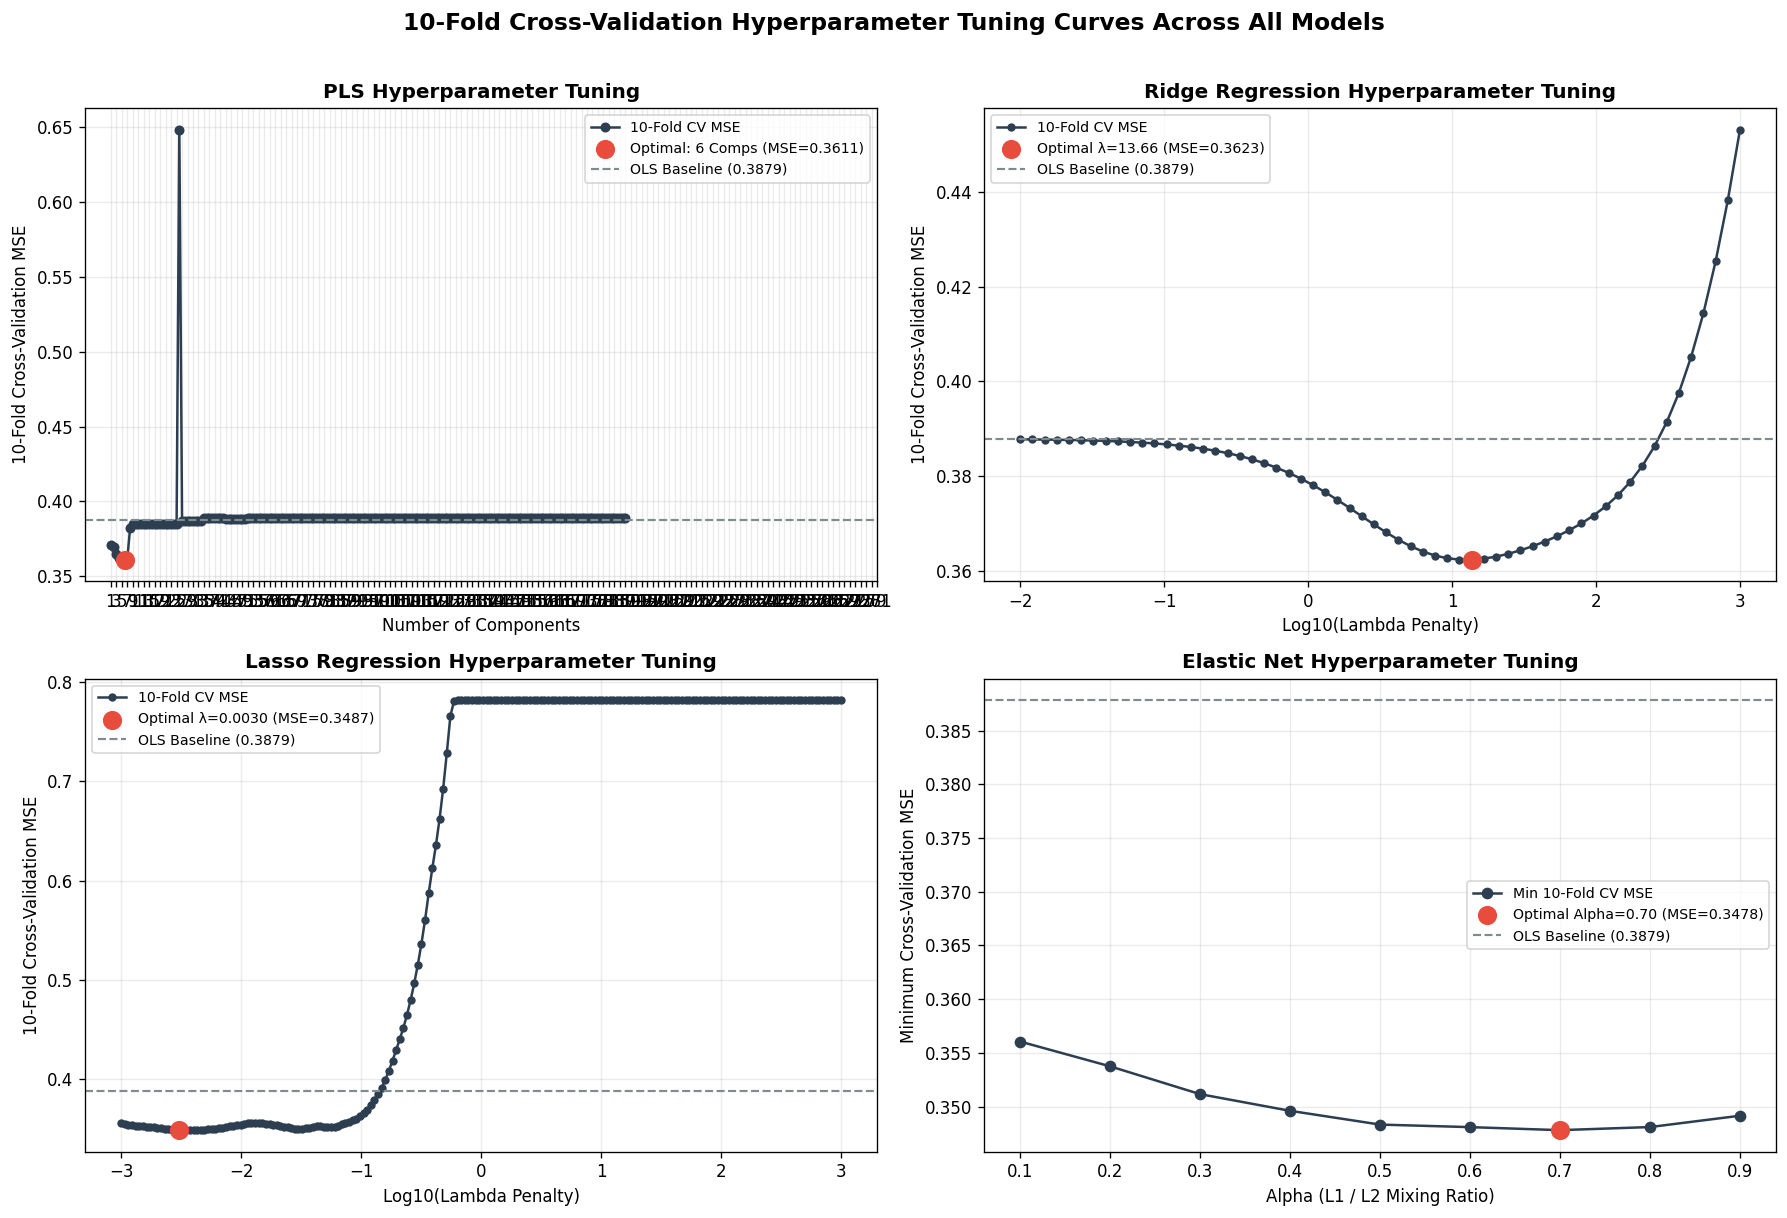

In [32]:
# ==============================================================================
# HYPERPARAMETER TUNING CURVES ACROSS ALL TUNABLE MODELS
# Report Alignment: Section e (Tuning Procedure) & Section g (Tuning Plots)
# Note: OLS has no tuning parameter and is shown as a horizontal baseline.
# ==============================================================================

from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

# 1. Compute 10-Fold CV MSE for OLS (Unregularized Baseline Reference)
ols_cv_mse = -cross_val_score(
    ols_pipe, X_train, y_train_log, cv=cv_10, scoring="neg_mean_squared_error"
).mean()

# 2. Extract 10-Fold CV MSE Curve for PLS (across n_components = 1 to 19)
pls_comps = np.arange(1, X_train.shape[1] + 1)
pls_cv_mse = (-pls_tuner.cv_results_["mean_test_score"]) ** 2  # Convert RMSE to MSE
best_pls_comp = pls_tuner.best_params_["model__n_components"]
best_pls_mse = pls_cv_mse[best_pls_comp - 1]

# 3. Compute 10-Fold CV MSE Curve for Ridge (across log10(Lambda) grid)
ridge_lambdas = np.logspace(-2, 3, 60)
ridge_cv_mse = []
for lam in ridge_lambdas:
    temp_ridge = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=lam))])
    mse = -cross_val_score(temp_ridge, X_train, y_train_log, cv=cv_10, scoring="neg_mean_squared_error").mean()
    ridge_cv_mse.append(mse)
ridge_cv_mse = np.array(ridge_cv_mse)
best_ridge_idx = np.argmin(ridge_cv_mse)
best_ridge_lam = ridge_lambdas[best_ridge_idx]
best_ridge_mse = ridge_cv_mse[best_ridge_idx]

# 4. Extract 10-Fold CV MSE Curve for Lasso (from fitted LassoCV mse_path_)
lasso_model = lasso_pipe.named_steps["model"]
lasso_lambdas = lasso_model.alphas_
lasso_cv_mse = lasso_model.mse_path_.mean(axis=1)
best_lasso_lam = lasso_model.alpha_
best_lasso_mse = lasso_cv_mse.min()

# 5. Extract 10-Fold CV MSE Curve for Elastic Net (Min CV MSE per Alpha / l1_ratio)
enet_model = enet_pipe.named_steps["model"]
enet_l1_ratios = enet_model.l1_ratio  # Grid from 0.1 to 0.9
# mse_path_ shape is (n_l1_ratios, n_alphas, n_folds) -> mean over folds, min over alphas
enet_min_mse_per_ratio = enet_model.mse_path_.mean(axis=2).min(axis=1)
best_enet_ratio = enet_model.l1_ratio_
best_enet_mse = enet_min_mse_per_ratio.min()

# ==============================================================================
# PLOTTING: 2x2 HYPERPARAMETER TUNING GRID (STYLE MATCHING FIGURE 3)
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=120)

# --- Panel 1: PLS Tuning (Components vs. CV MSE) ---
axes[0, 0].plot(pls_comps, pls_cv_mse, marker="o", color="#2c3e50", lw=1.5, markersize=5, label="10-Fold CV MSE")
axes[0, 0].scatter([best_pls_comp], [best_pls_mse], color="#e74c3c", s=110, zorder=5,
                   label=f"Optimal: {best_pls_comp} Comps (MSE={best_pls_mse:.4f})")
axes[0, 0].axhline(ols_cv_mse, color="#7f8c8d", linestyle="--", lw=1.3, label=f"OLS Baseline ({ols_cv_mse:.4f})")
axes[0, 0].set_title("PLS Hyperparameter Tuning", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Number of Components", fontsize=10)
axes[0, 0].set_ylabel("10-Fold Cross-Validation MSE", fontsize=10)
axes[0, 0].set_xticks(range(1, X_train.shape[1] + 1, 2))
axes[0, 0].legend(fontsize=8.5)
axes[0, 0].grid(True, linestyle="-", alpha=0.25)

# --- Panel 2: Ridge Tuning (Log10 Lambda vs. CV MSE) ---
axes[0, 1].plot(np.log10(ridge_lambdas), ridge_cv_mse, marker="o", color="#2c3e50", lw=1.5, markersize=4, label="10-Fold CV MSE")
axes[0, 1].scatter([np.log10(best_ridge_lam)], [best_ridge_mse], color="#e74c3c", s=110, zorder=5,
                   label=f"Optimal λ={best_ridge_lam:.2f} (MSE={best_ridge_mse:.4f})")
axes[0, 1].axhline(ols_cv_mse, color="#7f8c8d", linestyle="--", lw=1.3, label=f"OLS Baseline ({ols_cv_mse:.4f})")
axes[0, 1].set_title("Ridge Regression Hyperparameter Tuning", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Log10(Lambda Penalty)", fontsize=10)
axes[0, 1].set_ylabel("10-Fold Cross-Validation MSE", fontsize=10)
axes[0, 1].legend(fontsize=8.5)
axes[0, 1].grid(True, linestyle="-", alpha=0.25)

# --- Panel 3: Lasso Tuning (Log10 Lambda vs. CV MSE) ---
axes[1, 0].plot(np.log10(lasso_lambdas), lasso_cv_mse, marker="o", color="#2c3e50", lw=1.5, markersize=4, label="10-Fold CV MSE")
axes[1, 0].scatter([np.log10(best_lasso_lam)], [best_lasso_mse], color="#e74c3c", s=110, zorder=5,
                   label=f"Optimal λ={best_lasso_lam:.4f} (MSE={best_lasso_mse:.4f})")
axes[1, 0].axhline(ols_cv_mse, color="#7f8c8d", linestyle="--", lw=1.3, label=f"OLS Baseline ({ols_cv_mse:.4f})")
axes[1, 0].set_title("Lasso Regression Hyperparameter Tuning", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Log10(Lambda Penalty)", fontsize=10)
axes[1, 0].set_ylabel("10-Fold Cross-Validation MSE", fontsize=10)
axes[1, 0].legend(fontsize=8.5)
axes[1, 0].grid(True, linestyle="-", alpha=0.25)

# --- Panel 4: Elastic Net Tuning (Alpha / l1_ratio vs. Min CV MSE) ---
axes[1, 1].plot(enet_l1_ratios, enet_min_mse_per_ratio, marker="o", color="#2c3e50", lw=1.5, markersize=6, label="Min 10-Fold CV MSE")
axes[1, 1].scatter([best_enet_ratio], [best_enet_mse], color="#e74c3c", s=110, zorder=5,
                   label=f"Optimal Alpha={best_enet_ratio:.2f} (MSE={best_enet_mse:.4f})")
axes[1, 1].axhline(ols_cv_mse, color="#7f8c8d", linestyle="--", lw=1.3, label=f"OLS Baseline ({ols_cv_mse:.4f})")
axes[1, 1].set_title("Elastic Net Hyperparameter Tuning", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Alpha (L1 / L2 Mixing Ratio)", fontsize=10)
axes[1, 1].set_ylabel("Minimum Cross-Validation MSE", fontsize=10)
axes[1, 1].legend(fontsize=8.5)
axes[1, 1].grid(True, linestyle="-", alpha=0.25)

plt.suptitle("10-Fold Cross-Validation Hyperparameter Tuning Curves Across All Models", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()
